In [1]:
import numpy as np

ratings = np.loadtxt("ml-32m/ratings.csv", delimiter = ",", skiprows= 1)

# ratings = ratings[:100000]

In [2]:
cols = ['userId', 'movieId', 'rating', 'timestamp']

col_to_ind = {col:ind for ind,col in enumerate(cols)}

In [3]:
users_to_index = {}
index_to_users = []

movies_to_index = {}
index_to_movies = []

data_by_users = []
data_by_movies = []

In [4]:
index_to_users = np.unique(ratings[:,col_to_ind["userId"]]).tolist()
users_to_index = {user:index for index,user in enumerate(index_to_users)}


index_to_movies = np.unique(ratings[:,col_to_ind["movieId"]]).tolist()
movies_to_index = {movie:index for index,movie in enumerate(index_to_movies)}

In [5]:
def process_user_ratings(ratings_arr,index_to_users):
  data_by_users =  [[] for _ in range(len(index_to_users))]

  for row in ratings_arr:
    user = row[col_to_ind["userId"]]
    movie = row[col_to_ind["movieId"]]
    rating = row[col_to_ind["rating"]]

    data_by_users[users_to_index[user]].append((movies_to_index[movie],rating))

  return data_by_users

#data_by_users = process_user_ratings(ratings,index_to_users)

In [6]:
def process_movie_ratings(ratings_arr,index_to_movies):
  data_by_movies =  [[] for _ in range(len(index_to_movies))]

  for row in ratings_arr:
    user = row[col_to_ind["userId"]]
    movie = row[col_to_ind["movieId"]]
    rating = row[col_to_ind["rating"]]

    data_by_movies[movies_to_index[movie]].append((users_to_index[user],rating))

  return data_by_movies

#data_by_movies = process_movie_ratings(ratings,index_to_movies)

In [7]:
# splitting into train and test
import random

random.seed(42)

CUTOFF = 0.7

random_nums = [random.uniform(0,1) > CUTOFF for i in range(ratings.shape[0])]

test_locs = [i for i,j in enumerate(random_nums) if j]
train_locs = [i for i,j in enumerate(random_nums) if not j]

print(len(test_locs))
print(len(train_locs))

ratings_test = ratings[test_locs]
ratings_train = ratings[train_locs]

9595382
22404822


In [8]:
data_by_users_train = process_user_ratings(ratings_train, index_to_users)

data_by_users_test = process_user_ratings(ratings_test, index_to_users )

In [9]:
data_by_movies_test = process_movie_ratings(ratings_test, index_to_movies)
data_by_movies_train =  process_movie_ratings(ratings_train, index_to_movies)


data_by_movies_train[:1]

[[(9, np.float64(2.5)),
  (10, np.float64(3.0)),
  (16, np.float64(4.0)),
  (18, np.float64(3.0)),
  (19, np.float64(5.0)),
  (22, np.float64(3.0)),
  (23, np.float64(4.0)),
  (27, np.float64(4.0)),
  (35, np.float64(3.0)),
  (45, np.float64(4.0)),
  (50, np.float64(3.5)),
  (53, np.float64(4.0)),
  (56, np.float64(4.0)),
  (58, np.float64(4.0)),
  (59, np.float64(3.0)),
  (63, np.float64(5.0)),
  (64, np.float64(2.0)),
  (66, np.float64(4.0)),
  (69, np.float64(4.0)),
  (75, np.float64(4.5)),
  (77, np.float64(4.0)),
  (82, np.float64(3.0)),
  (84, np.float64(4.0)),
  (86, np.float64(3.5)),
  (92, np.float64(4.0)),
  (94, np.float64(4.5)),
  (99, np.float64(5.0)),
  (106, np.float64(3.5)),
  (114, np.float64(4.0)),
  (118, np.float64(3.5)),
  (119, np.float64(5.0)),
  (127, np.float64(3.5)),
  (129, np.float64(3.0)),
  (130, np.float64(4.0)),
  (138, np.float64(4.0)),
  (147, np.float64(1.0)),
  (149, np.float64(4.0)),
  (156, np.float64(4.5)),
  (157, np.float64(4.0)),
  (162, np.flo

In [10]:
import numpy as np

user_biases = np.zeros(len(data_by_users_train))
movies_biases = np.zeros(len(data_by_movies_train))


N_ITER = 20
lamb = 0.09
gamma = 0.1
tau = 0.9
VERBOSITY = 1
K = 8
train_rmses = []
test_rmses = []
test_losses = []
train_losses = []

for _ in range(N_ITER):
  for i, item_ratings in enumerate(data_by_users_train):
    bias = 0
    item_counter = 0
    for (n,r) in item_ratings:
      bias += lamb * (r - movies_biases[n])
      item_counter += 1
    bias = bias / (lamb * item_counter + gamma)
    user_biases[i] = bias

  for i, item_ratings in enumerate(data_by_movies_train):
    bias = 0
    item_counter = 0
    for (n,r) in item_ratings:
      bias += lamb * (r - user_biases[n])
      item_counter += 1
    bias = bias / (lamb * item_counter + gamma)
    movies_biases[i] = bias

  error = 0
  loss = 0
  items_count = 0
  for i,ratings in enumerate(data_by_users_train):
    for (n,r) in ratings:
      pred = user_biases[i] + movies_biases[n]
      true = r
      error_ = (pred - true)**2
      error += error_
      loss += error_
      items_count += 1
  train_RMSE = (error/items_count) ** (1/2)
  train_rmses.append(train_RMSE)
  loss += (sum(user_biases**2) + sum(movies_biases**2)) * gamma
  train_loss = loss/items_count
  train_losses.append(train_loss)


  loss = 0
  error = 0
  items_count = 0
  for i,ratings in enumerate(data_by_users_test):
    for (n,r) in ratings:
      pred = user_biases[i] + movies_biases[n]
      true = r
      error_ = (pred - true)**2
      error += error_
      loss += error_
      items_count += 1
  test_RMSE = (error/items_count) ** (1/2)
  loss += (sum(user_biases**2) + sum(movies_biases**2)) * gamma
  test_loss = loss/items_count
  test_losses.append(test_loss)
  test_rmses.append(test_RMSE)

  if _ % VERBOSITY == 0:
    print(f"Round {_}:  Train RMSE: {train_RMSE} Test RMSE: {test_RMSE}")
    print(f"Round {_}:  Train loss: {train_loss} Test loss: {test_loss}")
print(f"After training:  Train RMSE: {train_RMSE} Test RMSE: {test_RMSE}")
print(f"After training:  Train loss: {train_loss} Test loss: {test_loss}")

Round 0:  Train RMSE: 0.8600700612125122 Test RMSE: 0.8707718412901374
Round 0:  Train loss: 0.7516426216627177 Test loss: 0.7860812391190284
Round 1:  Train RMSE: 0.8471386801179164 Test RMSE: 0.8578373768272747
Round 1:  Train loss: 0.72901702233516 Test loss: 0.7624406363632834
Round 2:  Train RMSE: 0.8467521435475088 Test RMSE: 0.857451276443033
Round 2:  Train loss: 0.7280879281864632 Test loss: 0.7611377822109996
Round 3:  Train RMSE: 0.8467319320023603 Test RMSE: 0.8574209914101123
Round 3:  Train loss: 0.7278295165933506 Test loss: 0.7605623876221601
Round 4:  Train RMSE: 0.8467013098159617 Test RMSE: 0.8573785860342881
Round 4:  Train loss: 0.7275663274603467 Test loss: 0.7599962182023051
Round 5:  Train RMSE: 0.8466689027757884 Test RMSE: 0.8573352030059065
Round 5:  Train loss: 0.7273062280209622 Test loss: 0.7594426430488773
Round 6:  Train RMSE: 0.8466387696041998 Test RMSE: 0.8572953492694747
Round 6:  Train loss: 0.7270549241819272 Test loss: 0.7589066651406666
Round 7: 

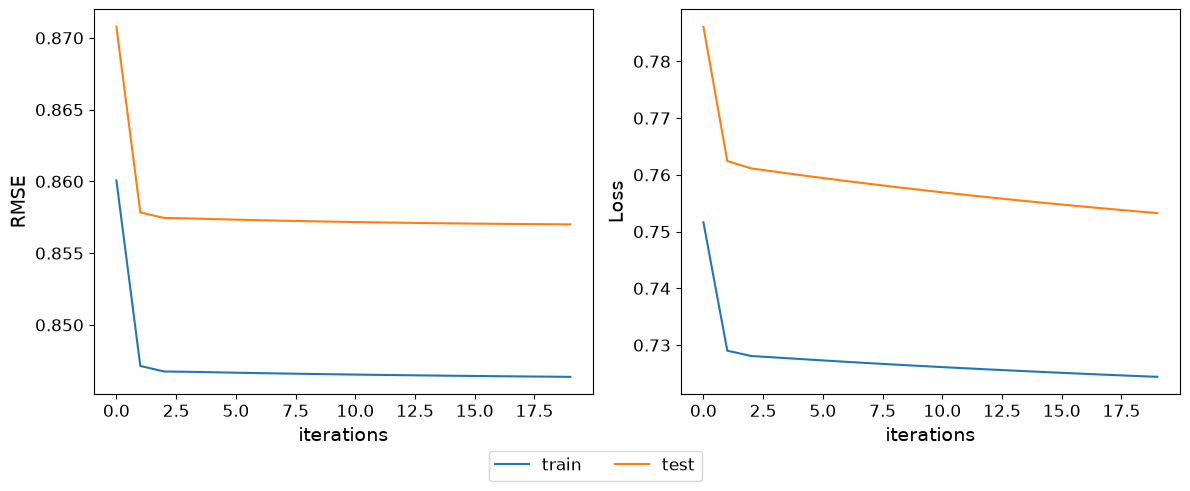

In [12]:
from matplotlib import pyplot as plt

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

fig,axs = plt.subplots(1,2, figsize = (12,5))

axs[0].plot(range(N_ITER), train_rmses, label = "train")
axs[0].plot(range(N_ITER), test_rmses, label = "test")
axs[0].set_ylabel("RMSE")
axs[0].set_xlabel("iterations")

axs[1].plot(range(N_ITER), train_losses, label = "train")
axs[1].plot(range(N_ITER), test_losses, label = "test")
axs[1].set_ylabel("Loss")
axs[1].set_xlabel("iterations")


handles, labels = axs[1].get_legend_handles_labels()

fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.01), fontsize = 12)

plt.tight_layout()
plt.subplots_adjust(bottom=0.2)

plt.savefig("images/bias_only_model_plot.svg")

plt.show()